## Spam data Classification


In [1]:
import os
# os.chdir("D:\\meridianthe4\\PML\\Datasets")
import pandas as pd
import re
import nltk 
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
dataset = pd.read_csv('D:\Machine Learning\Datasets\Cases\Spam_Classification\SPAM_Data.csv')
dataset.head()
corpus = []
stops = stopwords.words('english')
for i in range(0, dataset.shape[0]):
    review = re.sub('[^a-zA-Z]', ' ', dataset['Message'][i])
    review = review.lower()
    review = review.split()
    ps = PorterStemmer()
    review = [ps.stem(word) for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus.append(review)
corpus[:5]
### Count Vectorization
cv = CountVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Category']
X.head()
classifier = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))

### TF-IDF Vectorization
cv = TfidfVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier = RandomForestClassifier(n_estimators=25, random_state=25)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dbda.STUDENTSDC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Accuracy:  0.9838516746411483
Accuracy:  0.9796650717703349


In [28]:
# pos_rev = dataset[dataset['Category' == 'ham']]
neg_rev = dataset[dataset['Category']== 'spam']
pos_rev = pd.DataFrame(dataset[dataset['Category']== 'ham'])
print(pos_rev)



     Category                                            Message
0         ham  Go until jurong point, crazy.. Available only ...
1         ham                      Ok lar... Joking wif u oni...
3         ham  U dun say so early hor... U c already then say...
4         ham  Nah I don't think he goes to usf, he lives aro...
6         ham  Even my brother is not like to speak with me. ...
...       ...                                                ...
5565      ham                                       Huh y lei...
5568      ham               Will ü b going to esplanade fr home?
5569      ham  Pity, * was in mood for that. So...any other s...
5570      ham  The guy did some bitching but I acted like i'd...
5571      ham                         Rofl. Its true to its name

[4825 rows x 2 columns]


In [29]:
corpus = []
stops = stopwords.words('english')
for i in range(0,pos_rev.shape[0]):
    review = re.sub('[^a-zA-Z]','',pos_rev['Message'][i])
    review = review.lower()
    review = review.split()
    # ps = PorterStemmer()
    review = [word for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus.append(review)
corpus[:6]

KeyError: 2

In [12]:
corp_str = str(corpus)
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(relative_scaling=1.0).generate(corp_str)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

ValueError: We need at least 1 word to plot a word cloud, got 0.

In [32]:
corpus2 = []
stops = stopwords.words('english')
for i in range(0,neg_rev.shape[0]):
    review = re.sub('[^a-zA-Z]','',neg_rev['Message'].iloc[i])
    review = review.lower()
    review = review.split()
    ps = PorterStemmer()
    review = [ps.stem(word) for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus2.append(review)
corpus2[:6]

['freeentryinawklycomptowinfacupfinaltktsstmaytextfatotoreceiveentryquestionstdtxtratetcsapplyov',
 'freemsgheytheredarlingitsbeenweeksnowandnowordbackidlikesomefunyouupforitstilltbokxxxstdchgstosendtorcv',
 'winnerasavaluednetworkcustomeryouhavebeenselectedtoreceiveaprizerewardtoclaimcallclaimcodeklvalidhoursonli',
 'hadyourmobilemonthsormoreurentitledtoupdatetothelatestcolourmobileswithcameraforfreecallthemobileupdatecofreeon',
 'sixchancestowincashfromtopoundstxtcshandsendtocostpdaydaystsandcsapplyreplyhlinfo',
 'urgentyouhavewonaweekfreemembershipinourprizejackpottxtthewordclaimtonotcwwwdbuknetlccltdpoboxldnwarw']

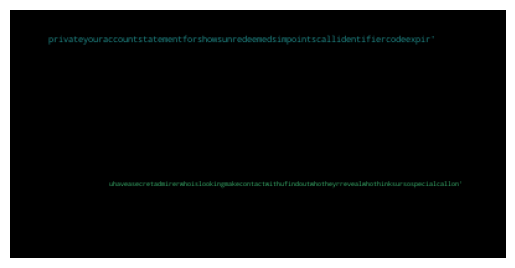

In [33]:
corp_str = str(corpus2)
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(relative_scaling=1.0).generate(corp_str)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dbda.STUDENTSDC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Accuracy:  0.9838516746411483
Accuracy:  0.9796650717703349


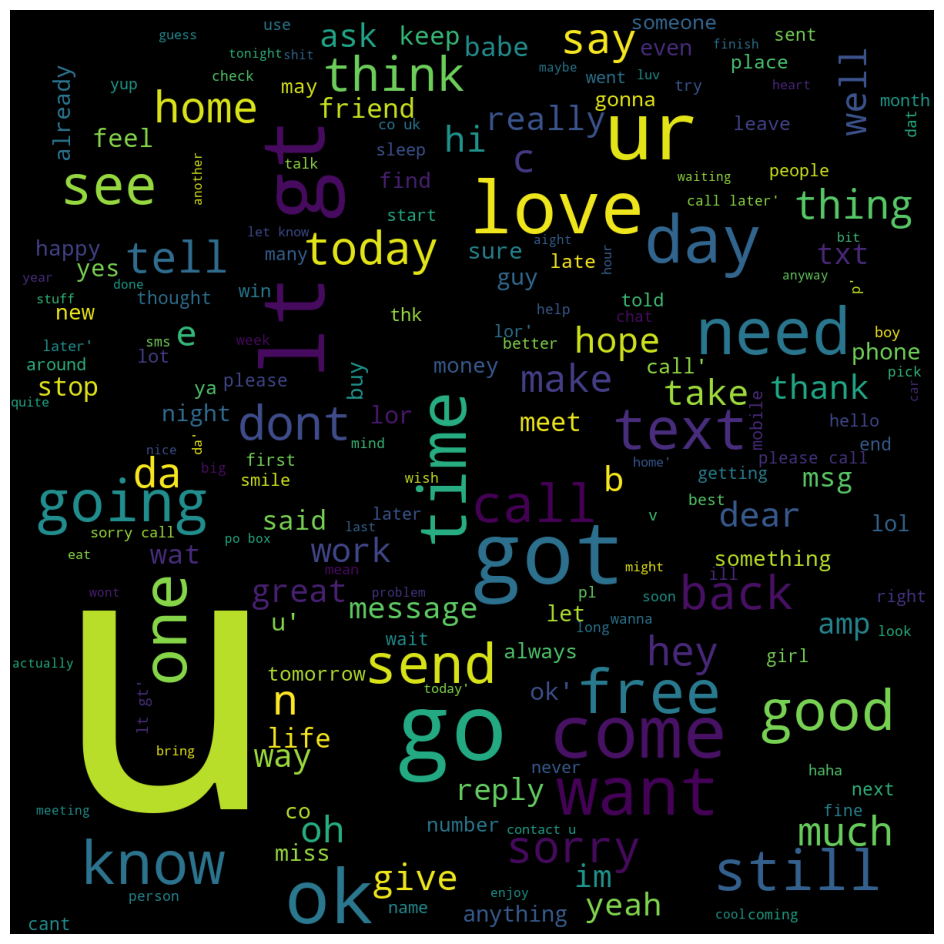

In [5]:
import os
# os.chdir("D:\\meridianthe4\\PML\\Cases-AI-1\\Spam_Classification")
import pandas as pd
import re
import nltk 
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
# dataset = pd.read_csv("SPAM_Data.csv")
dataset.head()
corpus = []
stops = stopwords.words('english')
for i in range(0, dataset.shape[0]):
    review = re.sub('[^a-zA-Z]', ' ', dataset['Message'][i])
    review = review.lower()
    review = review.split()
    ps = PorterStemmer()
    review = [ps.stem(word) for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus.append(review)
corpus[:5]
### Count Vectorization
cv = CountVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Category']
X.head()
classifier = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))

### TF-IDF Vectorization
cv = TfidfVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier = RandomForestClassifier(n_estimators=25, random_state=25)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))
### WordCloud
corpus2 = []
for i in range(0, dataset.shape[0]):
    review = re.sub('[^a-zA-Z]', ' ', dataset['Message'][i])
    review = review.lower()
    review = review.split()
    review = [word for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus2.append(review)
corpus2[:6]
corp_str = str(corpus2)
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(relative_scaling=1.0, width=1200, height=1200).generate(corp_str)
plt.figure(figsize=(12,12))
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

In [9]:

corpus2 = []
for i in range(0, pos_rev.shape[0]):
    review = re.sub('[^a-zA-Z]', ' ', pos_rev['Message'][i])
    review = review.lower()
    review = review.split()
    review = [word for word in review]
    review = ' '.join(review)
    corpus2.append(review)
corpus2[:6]
corp_str = str(corpus2)
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(relative_scaling=1.0, width=1200, height=1200).generate(corp_str)
plt.figure(figsize=(12,12))
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

ValueError: We need at least 1 word to plot a word cloud, got 0.